# AI, Data Science and Software Development Employment – Visualisations

This notebook uses the **U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS)** "All data" files from https://www.bls.gov/oes/tables.htm to explore employment in jobs involving **AI, Data Science and Software Development**.

- **Part 1 (visualisations 1–6):** a detailed snapshot of **May 2023** (`all_data_M_2023.xlsx`).
- **Part 2 (visualisations 7–11, challenge):** **trends over time**, using **six years of data, May 2020 to May 2025** (`all_data_M_2020.xlsx` … `all_data_M_2025.xlsx`).

All six Excel files must be in the same folder as this notebook. Running the whole notebook takes about 10 minutes because each file takes 1–2 minutes to load.
Each row of the dataset is one occupation in one area (the whole U.S., a state or a city) and one industry. For each row it gives the **number of people employed** (`TOT_EMP`) and their **wages** (`A_MEDIAN` = median yearly salary, plus the 10th/25th/75th/90th percentiles).

For each visualisation, we explain:

1. The **objective** of the visualisation (what we want to see).
2. **Why that visualisation type was chosen** (categorical, numerical, relationships).
3. **What we learned** about AI employment from the plot.

**Which jobs count as "AI"?** The BLS has no job called "AI Engineer", so we use the nine occupations where AI work is done:

| Field | Occupations |
|---|---|
| **AI & Research** | Computer and Information Research Scientists (the people who invent new AI and machine-learning methods) |
| **Data Science** | Data Scientists, Statisticians, Operations Research Analysts, Mathematicians, Database Architects |
| **Software Development** | Software Developers, Software Quality Assurance Analysts and Testers, Web Developers |

⚠️ *Limitation:* many machine-learning engineers are counted as "Software Developers" or "Data Scientists", so these numbers approximate AI jobs and are not an exact count.

> **Version 08 of 10.** What changed in this version: Added **Visualisation 8** (pay before/after inflation, using the CPI) and **Visualisation 9** (winners and losers after ChatGPT).
>
> <details><summary>Version history</summary>
>
> - **v01** – Project set-up: introduction, loading the May 2023 BLS data, cleaning (`*`, `**`, `#`) and selecting the nine AI / data / software jobs.
> - **v02** – Added **Visualisation 1** – horizontal bar chart of employment by job, with explanation.
> - **v03** – Added **Visualisation 2** – salary boxplot built from the published percentiles, with explanation.
> - **v04** – Added **Visualisation 3** – histogram comparing our jobs with the salaries of all U.S. occupations.
> - **v05** – Added **Visualisation 4** (pie chart of industries) and **Visualisation 5** (heatmap of states).
> - **v06** – Added **Visualisation 6** (city scatter plot) and the **Part 1 summary** – the 2023 snapshot is complete.
> - **v07** – Started **Part 2 (challenge)**: loaded five more years (2020–2025), matched the 2020 job codes, added **Visualisation 7** (growth line chart).
> - **v08** – Added **Visualisation 8** (pay before/after inflation, using the CPI) and **Visualisation 9** (winners and losers after ChatGPT).
>
> </details>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset (keep this notebook in the same folder as the Excel file – loading takes 1-2 minutes)
df = pd.read_excel("all_data_M_2023.xlsx")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


### Cleaning the data
Some number columns contain symbols instead of numbers:
- `*` or `**` = the value was not published (too few survey answers), so we turn it into a missing value (`NaN`).
- `#` = the salary is **\$239,200 or more** (the highest value the BLS publishes), so we replace it with 239200.

In [2]:
number_columns = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

for col in number_columns:
    df[col] = df[col].replace("#", 239200)
    df[col] = pd.to_numeric(df[col], errors="coerce")   # '*' and '**' become NaN

# The nine AI / Data Science / Software Development jobs and the field each belongs to
fields = {
    "Computer and Information Research Scientists": "AI & Research",
    "Data Scientists": "Data Science",
    "Statisticians": "Data Science",
    "Operations Research Analysts": "Data Science",
    "Mathematicians": "Data Science",
    "Database Architects": "Data Science",
    "Software Developers": "Software Development",
    "Software Quality Assurance Analysts and Testers": "Software Development",
    "Web Developers": "Software Development",
}

# National data (AREA_TYPE 1 = whole U.S.), all industries together, detailed job level only
# (O_GROUP "detailed" avoids double counting - some jobs also appear as a "broad" summary row)
usa = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "cross-industry") & (df["O_GROUP"] == "detailed")]

# Keep only our nine jobs and add the field column
tech = usa[usa["OCC_TITLE"].isin(fields.keys())].copy()
tech["Field"] = tech["OCC_TITLE"].map(fields)

tech[["OCC_TITLE", "Field", "TOT_EMP", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,OCC_TITLE,Field,TOT_EMP,A_MEDIAN
149,Software Developers,Software Development,1656880.0,132270.0
150,Software Quality Assurance Analysts and Testers,Software Development,203040.0,101800.0
165,Data Scientists,Data Science,192710.0,108020.0
161,Operations Research Analysts,Data Science,117880.0,83640.0
151,Web Developers,Software Development,85350.0,84960.0
145,Database Architects,Data Science,59920.0,134700.0
138,Computer and Information Research Scientists,AI & Research,35210.0,145080.0
163,Statisticians,Data Science,29950.0,104110.0
159,Mathematicians,Data Science,2220.0,116440.0


## 1. Horizontal Bar Chart – Number of People Employed in Each Job

Field
AI & Research             35210.0
Data Science             402680.0
Software Development    1945270.0
Name: TOT_EMP, dtype: float64
Total: 2383160.0


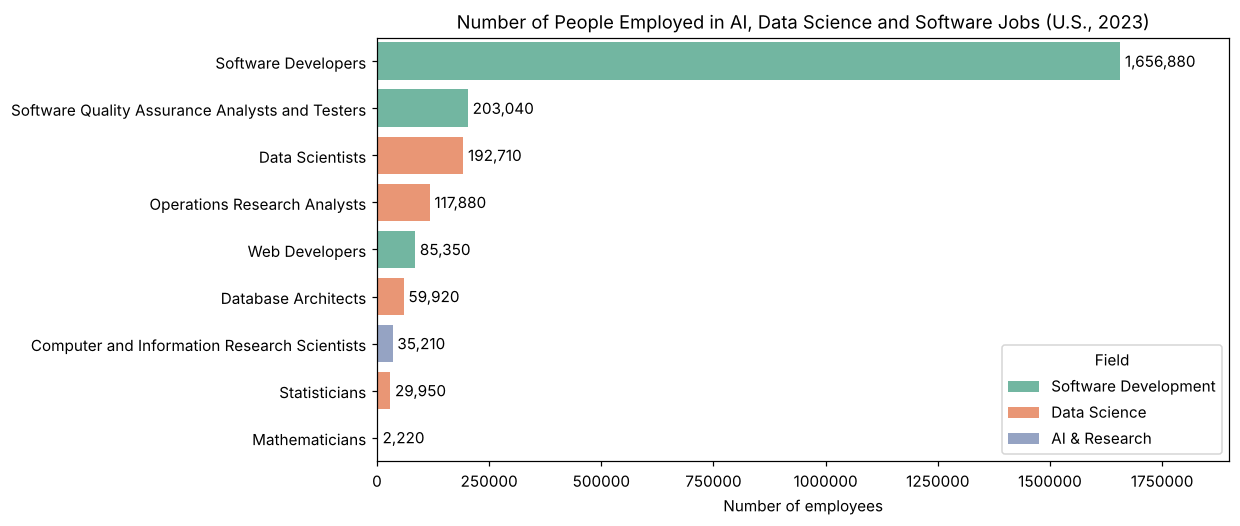

In [3]:
tech = tech.sort_values("TOT_EMP", ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x="TOT_EMP", y="OCC_TITLE", hue="Field", data=tech, dodge=False, palette="Set2")
for bars in ax.containers:                       # write the exact number at the end of each bar
    ax.bar_label(bars, fmt="{:,.0f}", padding=3)
plt.xlim(0, 1900000)
plt.title("Number of People Employed in AI, Data Science and Software Jobs (U.S., 2023)")
plt.xlabel("Number of employees")
plt.ylabel("")
plt.ticklabel_format(style="plain", axis="x")   # show 1600000 instead of 1.6 x 1e6
plt.show()

print(tech.groupby("Field")["TOT_EMP"].sum())
print("Total:", tech["TOT_EMP"].sum())

- **Objective:** Compare how many people work in each job and in each field (comparison).
- **Why this plot:** Each job is a category and its employment is a number, and bar length shows numbers accurately. The bars are horizontal because the job titles are long and are easier to read this way. They are sorted from largest to smallest, and the colour shows which field each job belongs to.
- **Learning:**
  - **Software Developers (about 1.66 million)** are by far the largest group, about **70 %** of everyone in these nine jobs.
  - **Data Scientists (about 193,000)** are the main data/AI job. There is about **one data scientist for every 8–9 software developers**.
  - **Computer and Information Research Scientists**, the closest match to "AI researcher", are only **about 35,000** people. Dedicated AI research is a very small, specialised workforce.
  - All nine jobs together are **about 2.4 million people, about 1.6 % of all U.S. jobs**. Most AI work is done by people with the job title "software developer" or "data scientist".

## 2. Boxplot – Salary Range for Each Job

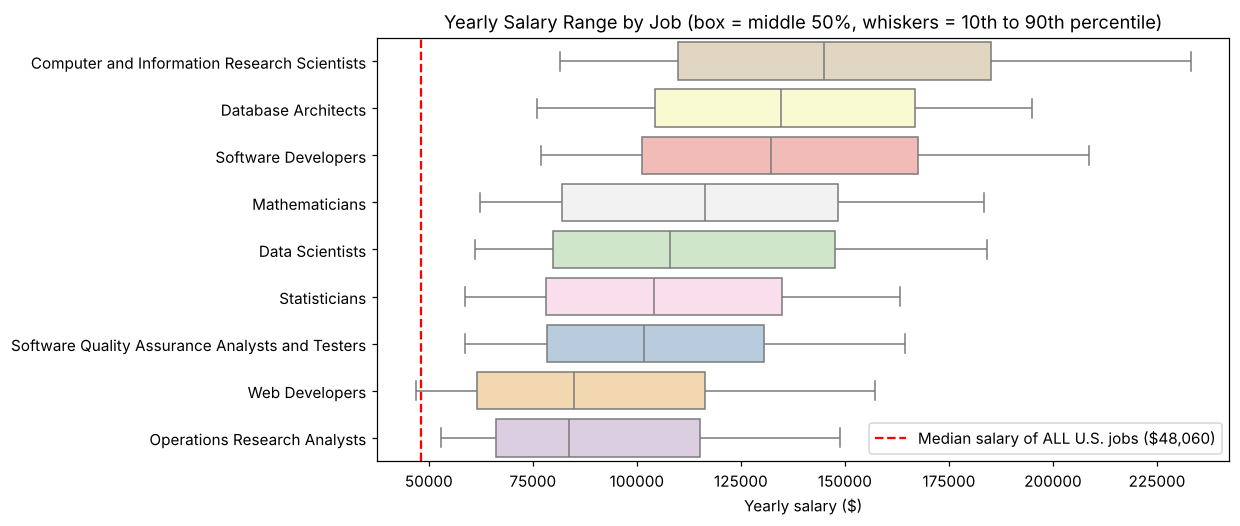

,OCC_TITLE,A_PCT10,A_MEDIAN,A_PCT90
138,Computer and Information Research Scientists,81450.0,145080.0,233110.0
145,Database Architects,76000.0,134700.0,194960.0
149,Software Developers,77020.0,132270.0,208620.0
159,Mathematicians,62260.0,116440.0,183500.0
165,Data Scientists,61070.0,108020.0,184090.0
163,Statisticians,58690.0,104110.0,163360.0
150,Software Quality Assurance Analysts and Testers,58740.0,101800.0,164520.0
151,Web Developers,46850.0,84960.0,157280.0
161,Operations Research Analysts,52930.0,83640.0,148920.0


In [4]:
# The dataset gives 5 salary points per job (10th, 25th, 50th, 75th, 90th percentile).
# We put them in long format so seaborn can draw a box for each job.
salaries = tech.melt(id_vars="OCC_TITLE",
                     value_vars=["A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"],
                     value_name="Salary")
order = tech.sort_values("A_MEDIAN", ascending=False)["OCC_TITLE"]

plt.figure(figsize=(10, 5))
sns.boxplot(x="Salary", y="OCC_TITLE", data=salaries, order=order, whis=(0, 100),
            hue="OCC_TITLE", palette="Pastel1", legend=False)
plt.axvline(48060, color="red", linestyle="--", label="Median salary of ALL U.S. jobs ($48,060)")
plt.title("Yearly Salary Range by Job (box = middle 50%, whiskers = 10th to 90th percentile)")
plt.xlabel("Yearly salary ($)")
plt.ylabel("")
plt.legend()
plt.show()

tech[["OCC_TITLE", "A_PCT10", "A_MEDIAN", "A_PCT90"]].sort_values("A_MEDIAN", ascending=False)

- **Objective:** Compare salaries across the jobs, and see how wide the pay range is inside each job (comparison and distribution).
- **Why this plot:** A boxplot shows the **median, the spread and the low and high ends** together, so it gives more information than a bar of the average. The BLS gives exactly the five numbers a boxplot needs (10th, 25th, 50th, 75th and 90th percentiles), so each box is drawn from those points. The red dashed line marks the median salary of *all* U.S. jobs for comparison.
- **Learning:**
  - **Every job's box is to the right of the red line.** Even the lowest-paid workers (10th percentile) in these jobs earn more than half of all U.S. workers.
  - **Computer and Information Research Scientists** (AI research) have the **highest median salary, about \$145,000**, which is **3 times** the U.S. median.
  - **Database Architects (\$135k)** and **Software Developers (\$132k)** come next. **Data Scientists (\$108k)** have a wide range (\$61k to \$184k), which shows a big difference between junior and senior roles.
  - **Web Developers** and **Operations Research Analysts** are the lowest-paid of the nine, at about \$84–85k.
  - The more specialised the job (research, architecture), the higher the pay.

## 3. Histogram – Salaries of All U.S. Jobs Compared with AI/Tech Jobs

Software Developers: earns more than 93% of all occupations
Software Quality Assurance Analysts and Testers: earns more than 87% of all occupations
Data Scientists: earns more than 90% of all occupations
Operations Research Analysts: earns more than 77% of all occupations
Web Developers: earns more than 79% of all occupations
Database Architects: earns more than 94% of all occupations
Computer and Information Research Scientists: earns more than 95% of all occupations
Statisticians: earns more than 88% of all occupations
Mathematicians: earns more than 91% of all occupations


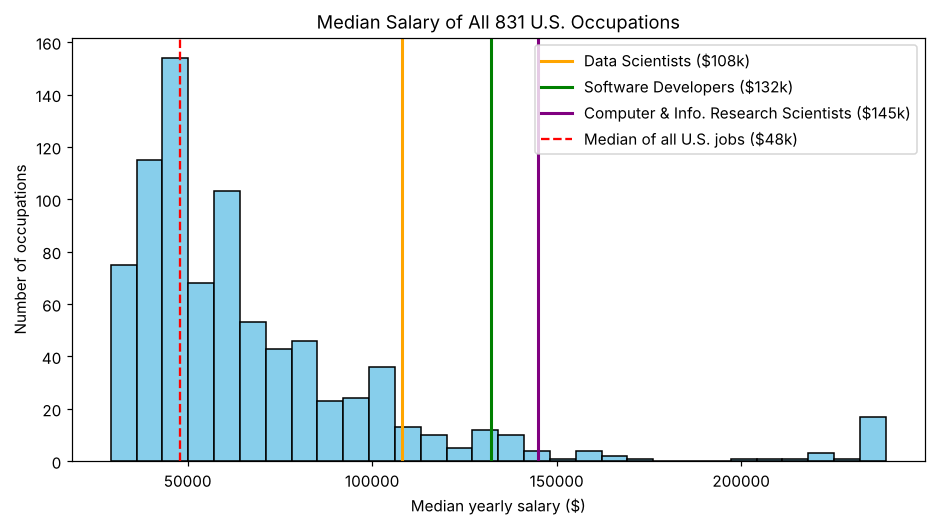

In [5]:
# Median salary of every detailed occupation in the U.S.
all_jobs = usa

plt.figure(figsize=(10, 5))
plt.hist(all_jobs["A_MEDIAN"].dropna(), bins=30, color="skyblue", edgecolor="black")

# Mark three of our jobs with vertical lines
plt.axvline(108020, color="orange", linewidth=2, label="Data Scientists ($108k)")
plt.axvline(132270, color="green", linewidth=2, label="Software Developers ($132k)")
plt.axvline(145080, color="purple", linewidth=2, label="Computer & Info. Research Scientists ($145k)")
plt.axvline(48060, color="red", linestyle="--", label="Median of all U.S. jobs ($48k)")

plt.title("Median Salary of All " + str(len(all_jobs)) + " U.S. Occupations")
plt.xlabel("Median yearly salary ($)")
plt.ylabel("Number of occupations")
plt.legend()
plt.show()

# What percentage of all occupations earn LESS than each of our jobs?
for job, salary in zip(tech["OCC_TITLE"], tech["A_MEDIAN"]):
    pct = (all_jobs["A_MEDIAN"] < salary).mean() * 100
    print(f"{job}: earns more than {pct:.0f}% of all occupations")

- **Objective:** Compare AI/tech salaries with **every** U.S. occupation, to see whether they really are high-paying jobs (comparison with context).
- **Why this plot:** Median salary is a continuous number, and there are about 830 occupations. A histogram groups them into salary ranges and shows the **shape** of the whole distribution. The coloured lines show where our jobs sit within it.
- **Learning:**
  - Most U.S. occupations have a median salary between **\$35,000 and \$70,000**. The distribution is **right-skewed**, with only a few jobs above \$100k.
  - Our jobs are in the **high-pay tail**. Research Scientists earn more than **95 %** of all occupations, Software Developers **93 %** and Data Scientists **90 %**. Even the lowest-paid, Web Developers and Operations Research Analysts, beat about **77–79 %**.
  - Almost all of the jobs that pay more are **doctors, surgeons and dentists**, plus **pilots, chief executives, senior managers and lawyers**.
  - Apart from medicine, law and senior management, AI and software jobs are among the best-paid in the country.

## 4. Pie Chart – Which Industries Employ Data Scientists

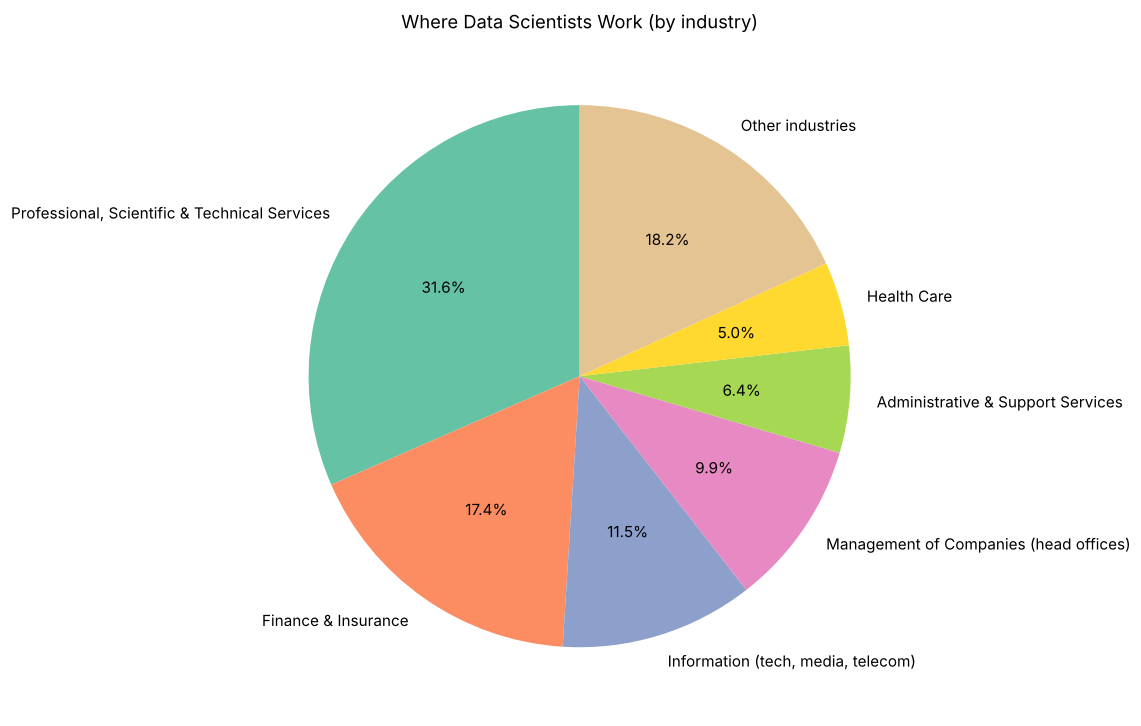

NAICS_TITLE
Professional, Scientific, and Technical Services                            60800.0
Finance and Insurance                                                       33620.0
Information                                                                 22240.0
Management of Companies and Enterprises                                     19060.0
Administrative and Support and Waste Management and Remediation Services    12310.0
Health Care and Social Assistance                                            9650.0
Other industries                                                            35010.0
Name: TOT_EMP, dtype: float64

In [6]:
# National data split by industry sector, for Data Scientists only
ds_industry = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "sector") & (df["O_GROUP"] == "detailed")
                 & (df["OCC_TITLE"] == "Data Scientists")]
ds_industry = ds_industry.set_index("NAICS_TITLE")["TOT_EMP"].sort_values(ascending=False)

# Keep the 6 biggest industries and group the rest into "Other"
top6 = ds_industry.head(6)
top6["Other industries"] = ds_industry[6:].sum()

labels = ["Professional, Scientific & Technical Services", "Finance & Insurance", "Information (tech, media, telecom)",
          "Management of Companies (head offices)", "Administrative & Support Services", "Health Care", "Other industries"]

plt.figure(figsize=(8, 8))
plt.pie(top6, labels=labels, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
plt.title("Where Data Scientists Work (by industry)")
plt.show()

top6

- **Objective:** Show which industries Data Scientists, the main AI/ML job, work in (whole-part relationship).
- **Why this plot:** Pie charts are good for whole-part relationships, here how 100 % of data scientists are split across industries. To keep it readable, only the **6 biggest industries** are shown and the rest are grouped into "Other".
- **Learning:**
  - **Professional, Scientific & Technical Services** (consulting, IT services, research companies) employ the most, about **one-third**. Much AI work is done as a *service* for other companies.
  - **Finance & Insurance (about 17 %)** is second. Banks and insurers use data science for fraud detection, credit risk and pricing.
  - **Information** (software, internet, telecom) and **company head offices** each employ about 10–12 %.
  - **Health care (5 %)**, manufacturing (4 %) and government (2 %) employ only a small share. AI talent is concentrated in a few industries, and other sectors still have room to grow.

## 5. Heatmap – Which States Specialise in AI/Data/Software Jobs

The **Location Quotient (LQ)** compares a state with the national average:
**LQ = 1** means the same as the U.S. average, **LQ = 2** means twice as concentrated, and **LQ = 0.5** means half.

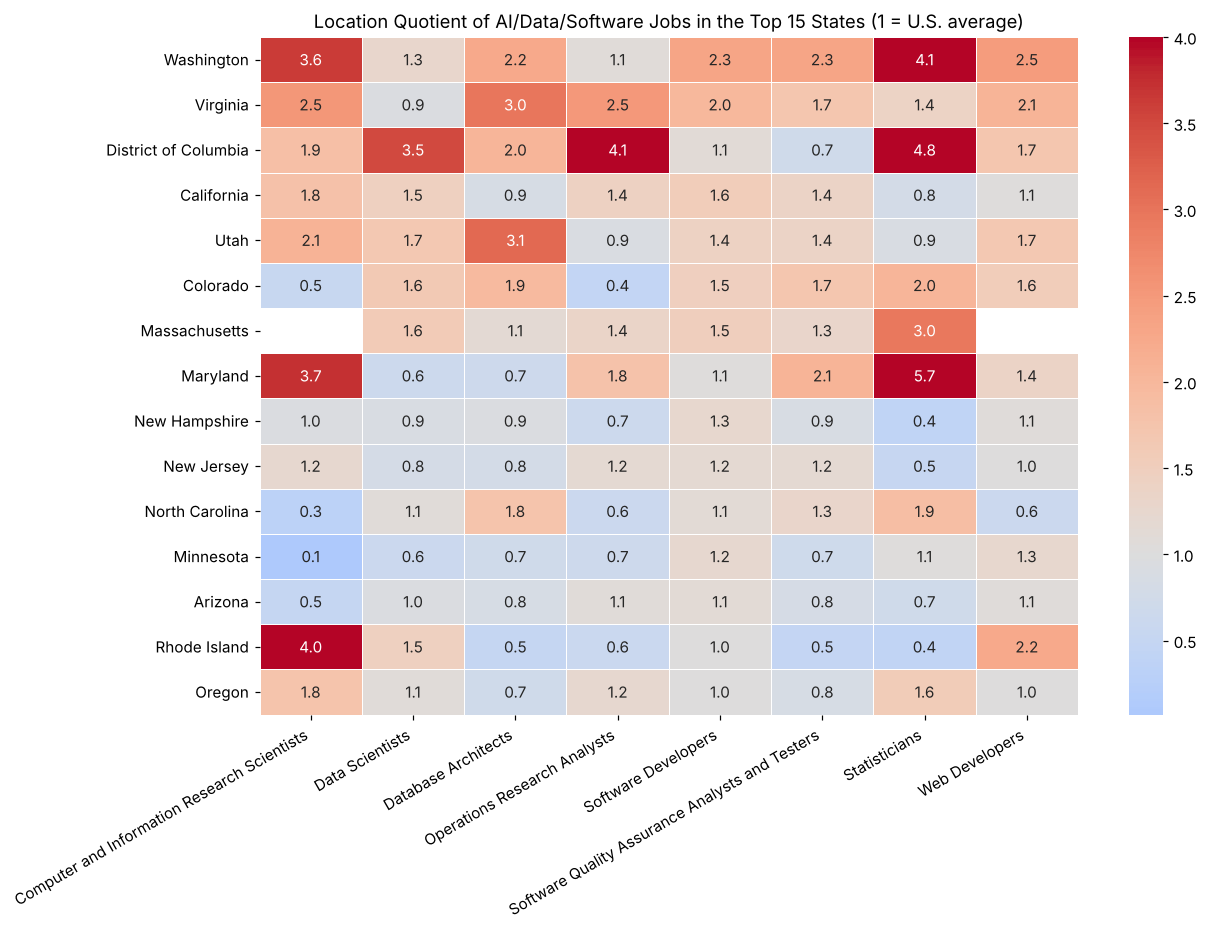

In [7]:
# State-level data (AREA_TYPE 2 = state), all industries, our nine jobs
states = df[(df["AREA_TYPE"] == 2) & (df["I_GROUP"] == "cross-industry") & (df["O_GROUP"] == "detailed")
            & (df["OCC_TITLE"].isin(fields.keys()))]

# Pick the 15 states with the most of these jobs per 1,000 workers
top_states = states.groupby("AREA_TITLE")["JOBS_1000"].sum().sort_values(ascending=False).head(15).index

# Table: rows = states, columns = jobs, values = location quotient (Mathematicians removed - mostly missing)
lq = states[states["AREA_TITLE"].isin(top_states)].pivot_table(index="AREA_TITLE", columns="OCC_TITLE", values="LOC_QUOTIENT")
lq = lq.drop(columns="Mathematicians").reindex(top_states)

plt.figure(figsize=(12, 8))
sns.heatmap(lq, annot=True, fmt=".1f", cmap="coolwarm", center=1, vmax=4, linewidths=0.5)
plt.title("Location Quotient of AI/Data/Software Jobs in the Top 15 States (1 = U.S. average)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=30, ha="right")
plt.show()

- **Objective:** Find which states have unusually many of these jobs, and whether a state is strong in every job or only some (comparison across two categories).
- **Why this plot:** The data is a table of 15 states × 8 jobs (120 numbers). A heatmap shows the whole table at once, and colour makes the patterns easy to see. **Red = above the national average, blue = below.** Each cell also shows its number (`annot=True`). Blank cells are missing data.
- **Learning:**
  - **Washington state** (Microsoft, Amazon) is **red in almost every column**, so it is strong in all types of tech work. Its Software Developer LQ (2.3) is the highest of any state.
  - **Washington D.C., Maryland and Virginia** have very high values for **Statisticians, Operations Research Analysts and Data Scientists** (D.C. Data Scientists = 3.5). The federal government and defence contractors create a "government data science" hub.
  - **Research Scientists** (AI research) are most concentrated in **Rhode Island (4.0), Maryland (3.7), Washington (3.6) and Virginia (2.5)**. Small states can get high values from only a few hundred jobs.
  - **California** has the largest *number* of these jobs, but relative to its huge economy it is about **1.5×** the average for Data Scientists and Software Developers, not the highest.
  - Lower down the list, cells turn **blue**. Most states are close to average for software jobs but below average for specialist AI/data jobs. AI jobs are **clustered in a few hubs**.

## 6. Scatterplot – Software Developer Concentration vs Salary in U.S. Cities

Correlation: 0.52


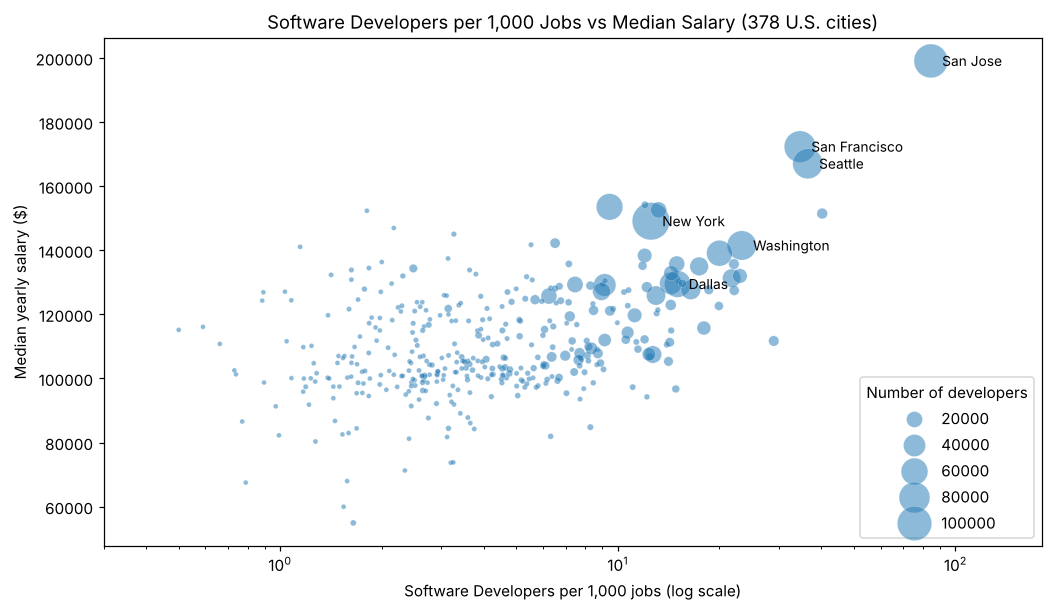

In [8]:
# City-level data (AREA_TYPE 4 = metropolitan area) for Software Developers
cities = df[(df["AREA_TYPE"] == 4) & (df["I_GROUP"] == "cross-industry") & (df["O_GROUP"] == "detailed")
             & (df["OCC_TITLE"] == "Software Developers")]
cities = cities.dropna(subset=["JOBS_1000", "A_MEDIAN"])

plt.figure(figsize=(11, 6))
sns.scatterplot(x="JOBS_1000", y="A_MEDIAN", size="TOT_EMP", sizes=(10, 600), alpha=0.5, data=cities)
plt.xscale("log")
plt.xlim(0.3, 180)                 # leave room for the city labels

# Label the 6 cities with the most software developers
for _, row in cities.nlargest(6, "TOT_EMP").iterrows():
    plt.text(row["JOBS_1000"] * 1.08, row["A_MEDIAN"], row["AREA_TITLE"].split("-")[0], fontsize=9, va="center")

plt.title("Software Developers per 1,000 Jobs vs Median Salary (" + str(len(cities)) + " U.S. cities)")
plt.xlabel("Software Developers per 1,000 jobs (log scale)")
plt.ylabel("Median yearly salary ($)")
plt.legend(title="Number of developers", loc="lower right")
plt.show()

print("Correlation:", round(cities["JOBS_1000"].corr(cities["A_MEDIAN"]), 2))

- **Objective:** Check whether cities with **more** software developers (relative to their size) also **pay them more** (relationship between two variables).
- **Why this plot:** Scatterplots show patterns between two continuous variables. Here they are concentration (developers per 1,000 jobs) and median salary. **Bubble size** adds a third variable, the number of developers. The x-axis uses a **log scale** because the values range from under 1 to over 80, and on a normal scale most cities would be squeezed together on the left.
- **Learning:**
  - There is a **positive relationship (correlation about 0.5)**. Cities with more software developers tend to pay them more.
  - **San Jose (Silicon Valley)** is far ahead of every other city: about **85 developers per 1,000 jobs** and a median salary of **\$199,000**. **San Francisco (\$172k)** and **Seattle (\$167k)** come next.
  - Most cities have fewer than 10 developers per 1,000 jobs and pay around **\$95k–\$125k**.
  - **New York** has the most developers (biggest bubble), but they are a smaller share of its huge economy.
  - Location matters a lot. The same job can pay about **twice as much** in a tech hub, but living costs are also higher there.

## Summary – Part 1 (May 2023 snapshot)

| # | Visualisation | Objective | What we learned |
|---|---|---|---|
| 1 | Horizontal bar chart | Compare job sizes | ~2.4 million people in total; Software Developers are ~70 %; AI research scientists are only ~35k |
| 2 | Boxplot | Compare salaries and their spread | All nine jobs pay far above the U.S. median; Research Scientists earn the most (~\$145k) |
| 3 | Histogram | Compare with all U.S. jobs | These jobs earn more than 77–95 % of all occupations |
| 4 | Pie chart | Industry split (whole-part) | Data Scientists work mostly in professional services, finance and tech |
| 5 | Heatmap | Compare states | Two kinds of hub: tech (WA, CA, UT, CO) and government (DC, MD, VA) |
| 6 | Scatterplot | Relationship | Cities with more developers tend to pay more; Silicon Valley is the top-paying city |

**Overall:** In 2023, AI work in the U.S. was done mainly by software developers and data scientists. These jobs are **very well paid** and **concentrated in a few industries and cities**.

**Limitations:** there is no official "AI engineer" job code, the data is for **one year only** (no trends), some values are missing, and salaries are not adjusted for cost of living.

---
# Part 2 (Challenge) – AI Employment Trends Over Time, 2020 → 2025

To see how AI-related employment is **changing**, we add five more "All data" files from the same BLS page (https://www.bls.gov/oes/tables.htm). Together with 2023 this gives **six years in a row**:

| File | Survey period | What was happening |
|---|---|---|
| `all_data_M_2020.xlsx` | May 2020 | COVID-19; before the generative-AI boom |
| `all_data_M_2021.xlsx` | May 2021 | Pandemic recovery; tech hiring boom begins |
| `all_data_M_2022.xlsx` | May 2022 | Peak tech hiring; six months *before* ChatGPT (Nov 2022) |
| `all_data_M_2023.xlsx` | May 2023 | Six months *after* ChatGPT; large tech layoffs – the dataset used in Part 1 |
| `all_data_M_2024.xlsx` | May 2024 | Companies start using generative AI more widely |
| `all_data_M_2025.xlsx` | May 2025 | Most recent data |

### Making the years comparable
From **2021 to 2025 every job uses exactly the same code**, so those years can be compared directly. **2020 is different:** the BLS used some combined ("hybrid") codes that year while it switched to the new 2018 job classification. So we match the codes into **groups that mean the same thing in every year**:

| Comparable group | 2020 code(s) | 2021–2025 code(s) |
|---|---|---|
| Research Scientists (AI) | 15-1221 | 15-1221 |
| Data Scientists | 15-2098 *Data Scientists and Mathematical Science Occupations, All Other* | 15-2051 Data Scientists + 15-2099 Mathematical Science Occupations, All Other |
| Software Developers & QA Testers | 15-1256 (one combined code) | 15-1252 + 15-1253 |
| Web Developers & Designers | 15-1257 (one combined code) | 15-1254 + 15-1255 |
| Database Admins & Architects | 15-1245 (one combined code) | 15-1242 + 15-1243 |
| Information Security Analysts | 15-1212 | 15-1212 |
| Statisticians / Operations Research Analysts / Mathematicians | same codes in every year | same codes in every year |
| Computer Programmers (added for comparison) | 15-1251 | 15-1251 |

⚠️ *Notes:* (1) In May 2020 total U.S. employment was unusually low because of **COVID-19**. (2) OEWS estimates come from a survey and are designed as yearly snapshots, so **small** year-to-year changes (a few %) should be read with care. The **large** changes found below are much bigger than this survey noise.

In [9]:
# Load the five extra years (each file takes 1-2 minutes). The 2023 data is already loaded as df.
files = {2020: "all_data_M_2020.xlsx", 2021: "all_data_M_2021.xlsx", 2022: "all_data_M_2022.xlsx",
         2024: "all_data_M_2024.xlsx", 2025: "all_data_M_2025.xlsx"}
years = {2023: df}
for year, file in files.items():
    years[year] = pd.read_excel(file)
    print("Loaded", year)

# Keep national, all-industry rows for each year and stack them into one table with a YEAR column
national = []
for year, data in years.items():
    data = data[(data["AREA_TYPE"] == 1) & (data["I_GROUP"] == "cross-industry")].copy()
    for col in ["TOT_EMP", "A_MEDIAN"]:
        data[col] = pd.to_numeric(data[col].replace("#", 239200), errors="coerce")
    data["YEAR"] = year
    national.append(data)
trend = pd.concat(national)

# Match the job codes of each year into comparable groups (see table above)
groups = {
    "15-1221": "Research Scientists (AI)",
    "15-2098": "Data Scientists", "15-2051": "Data Scientists", "15-2099": "Data Scientists",
    "15-1256": "Software Developers & QA", "15-1252": "Software Developers & QA", "15-1253": "Software Developers & QA",
    "15-1257": "Web Developers & Designers", "15-1254": "Web Developers & Designers", "15-1255": "Web Developers & Designers",
    "15-1245": "Database Admins & Architects", "15-1242": "Database Admins & Architects", "15-1243": "Database Admins & Architects",
    "15-1212": "Information Security Analysts",
    "15-2041": "Statisticians", "15-2031": "Operations Research Analysts", "15-2021": "Mathematicians",
    "15-1251": "Computer Programmers",
    "00-0000": "All U.S. jobs",
}
trend["GROUP"] = trend["OCC_CODE"].map(groups)

employment = trend.pivot_table(index="GROUP", columns="YEAR", values="TOT_EMP", aggfunc="sum")
employment["Change 2020-2025 (%)"] = (employment[2025] / employment[2020] - 1) * 100
employment["Change 2023-2025 (%)"] = (employment[2025] / employment[2023] - 1) * 100
employment.round(1).sort_values("Change 2020-2025 (%)", ascending=False)

Loaded 2020
Loaded 2021
Loaded 2022
Loaded 2024
Loaded 2025


YEAR,2020,2021,2022,2023,2024,2025,Change 2020-2025 (%),Change 2023-2025 (%)
GROUP,,,,,,,,
Data Scientists,59680.0,109950.0,163470.0,197030.0,238100.0,266160.0,346.0,35.1
Information Security Analysts,138000.0,157220.0,163690.0,175350.0,179430.0,190650.0,38.2,8.7
Software Developers & QA,1476800.0,1554300.0,1731210.0,1859920.0,1854240.0,1874630.0,26.9,0.8
Research Scientists (AI),30220.0,30840.0,33780.0,35210.0,38480.0,37200.0,23.1,5.7
Web Developers & Designers,156220.0,167200.0,185970.0,196410.0,190260.0,183520.0,17.5,-6.6
Operations Research Analysts,96220.0,98700.0,105080.0,117880.0,107760.0,108510.0,12.8,-7.9
All U.S. jobs,139099570.0,140886310.0,147886000.0,151853870.0,154187380.0,155495730.0,11.8,2.4
Database Admins & Architects,133630.0,136310.0,142990.0,136060.0,137950.0,137130.0,2.6,0.8
Mathematicians,2460.0,1770.0,2070.0,2220.0,2220.0,2030.0,-17.5,-8.6


## 7. Line Chart – Employment Growth Each Year, 2020–2025 (Index, 2020 = 100)

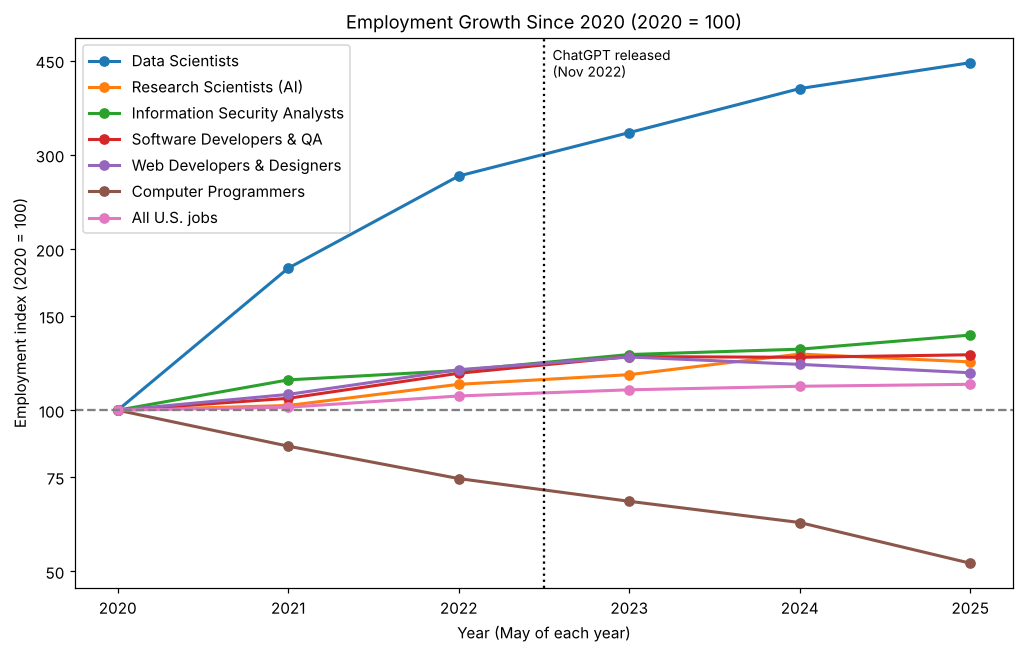

GROUP,Data Scientists,Research Scientists (AI),Information Security Analysts,Software Developers & QA,Web Developers & Designers,Computer Programmers,All U.S. jobs
YEAR,,,,,,,
2020,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2021,184.0,102.0,114.0,105.0,107.0,86.0,101.0
2022,274.0,112.0,119.0,117.0,119.0,75.0,106.0
2023,330.0,117.0,127.0,126.0,126.0,68.0,109.0
2024,399.0,127.0,130.0,126.0,122.0,62.0,111.0
2025,446.0,123.0,138.0,127.0,117.0,52.0,112.0


In [10]:
# Index: divide each year by its 2020 value and multiply by 100, so every job starts at 100.
# This lets us compare GROWTH RATES of big and small jobs on the same chart.
emp_by_year = employment[[2020, 2021, 2022, 2023, 2024, 2025]].T     # rows = years, columns = groups
emp_by_year.index = emp_by_year.index.astype(int)                    # make sure years are numbers
index = emp_by_year / emp_by_year.loc[2020] * 100

lines = ["Data Scientists", "Research Scientists (AI)", "Information Security Analysts", "Software Developers & QA",
         "Web Developers & Designers", "Computer Programmers", "All U.S. jobs"]

index[lines].plot(marker="o", figsize=(11, 6.5), linewidth=2)
plt.axhline(100, color="grey", linestyle="--")
plt.axvline(2022.5, color="black", linestyle=":")                     # ChatGPT released Nov 2022
plt.text(2022.55, 420, "ChatGPT released\n(Nov 2022)", fontsize=9)
plt.title("Employment Growth Since 2020 (2020 = 100)")
plt.xlabel("Year (May of each year)")
plt.ylabel("Employment index (2020 = 100)")
plt.yscale("log")                   # log scale so the huge Data Scientist growth doesn't squash the other lines
plt.minorticks_off()
plt.yticks([50, 75, 100, 150, 200, 300, 450], ["50", "75", "100", "150", "200", "300", "450"])
plt.legend(loc="upper left")
plt.show()

index[lines].round(0)

- **Objective:** Compare **how fast** each AI/tech job has grown **each year** since 2020 and see which jobs are rising or falling (trend over time).
- **Why this plot:** Line charts are the standard choice for showing change over **time**. With six yearly points we can see the **shape** of each trend: steady, speeding up, slowing down or reversing. The jobs are very different in size (1.9 million software developers vs 37 thousand research scientists), so each line is converted to an **index where 2020 = 100**. This compares *growth rates* rather than sizes. A **log scale** keeps the very fast Data Scientist line from squashing the others. The dotted vertical line marks the **release of ChatGPT** so we can compare "before" and "after".
- **Learning:**
  - **Data Scientists grew in every single year: 60k → 110k → 163k → 197k → 238k → 266k (index ≈ 446).** Even counting only 2021–2025, when the codes are identical, the number **more than doubled (+142 %)**. Growth slowed in percentage terms (+49 % in 2022, +12 % in 2025), but the job still added **between 28 and 54 thousand workers every year**, the clearest sign of the AI boom in the data.
  - **Software Developers & QA** grew quickly from 2020 to 2023 (index ≈ 126) and then **stopped growing: 1.86 M in 2023, 1.85 M in 2024, 1.87 M in 2025**. The line turns flat right after ChatGPT appeared and the 2023 tech layoffs began.
  - **Computer Programmers fell in every single year, from 178k to 92k (−48 %).** This is a steady long-term decline, not a one-off drop. Routine "write the code from a specification" work is the kind of task that AI coding assistants and offshoring are taking over.
  - **Information Security Analysts (+38 %)** and **Research Scientists (+23 %)** grew faster than all U.S. jobs (+12 %). Research Scientists dipped slightly in 2025 (38.5k → 37.2k), which is within normal survey variation.
  - **Web Developers & Designers** peaked in 2023 and have declined since.
  - **Overall:** after 2022 the lines **spread apart**. AI and data roles kept rising while routine coding roles fell. The AI boom has not grown *all* tech jobs; it has **moved** jobs between them.

## 8. Grouped Bar Chart – Pay Rises 2021–2025: Before and After Inflation

To know whether workers are really better off, we must remove **inflation**. We use the U.S. **Consumer Price Index (CPI-U, all items, not seasonally adjusted)** for **May** of each year, the same month as the OEWS survey (source: U.S. Bureau of Labor Statistics, https://www.bls.gov/cpi/):

| May 2020 | May 2021 | May 2022 | May 2023 | May 2024 | May 2025 |
|---|---|---|---|---|---|
| 256.394 | 269.195 | 292.296 | 304.127 | 314.069 | 321.465 |

**Real pay change** = (2025 salary ÷ 2025 CPI) ÷ (2021 salary ÷ 2021 CPI) − 1. We use **2021** as the starting year because from 2021 every job code is identical.

Prices rose 19.4% from May 2021 to May 2025
Prices rose 25.4% from May 2020 to May 2025


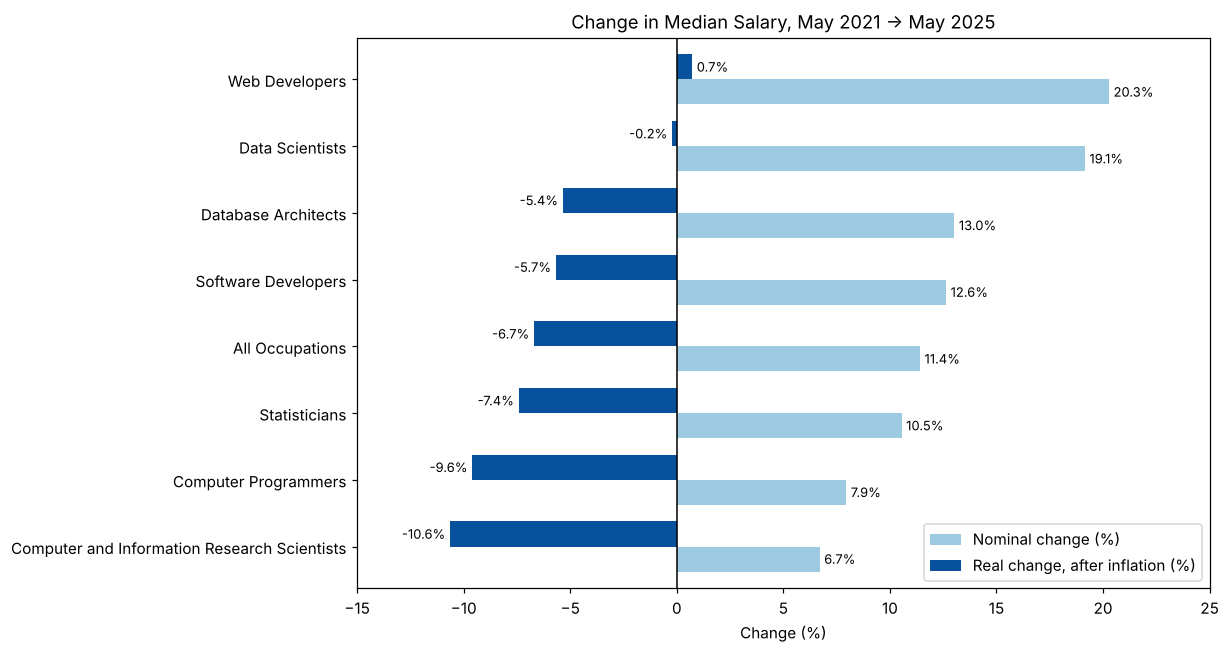

YEAR,2021,2025,Nominal change (%),"Real change, after inflation (%)"
OCC_TITLE,,,,
Computer and Information Research Scientists,131490.0,140300.0,6.7,-10.6
Computer Programmers,93000.0,100390.0,7.9,-9.6
Statisticians,95570.0,105650.0,10.5,-7.4
All Occupations,45760.0,50980.0,11.4,-6.7
Software Developers,120730.0,135980.0,12.6,-5.7
Database Architects,123430.0,139500.0,13.0,-5.4
Data Scientists,100910.0,120230.0,19.1,-0.2
Web Developers,77030.0,92650.0,20.3,0.7


In [11]:
cpi = {2020: 256.394, 2021: 269.195, 2022: 292.296, 2023: 304.127, 2024: 314.069, 2025: 321.465}
print(f"Prices rose {(cpi[2025] / cpi[2021] - 1) * 100:.1f}% from May 2021 to May 2025")
print(f"Prices rose {(cpi[2025] / cpi[2020] - 1) * 100:.1f}% from May 2020 to May 2025")

jobs = ["Data Scientists", "Software Developers", "Database Architects", "Computer and Information Research Scientists",
        "Statisticians", "Web Developers", "Computer Programmers", "All Occupations"]
pay = trend[trend["OCC_TITLE"].isin(jobs) & trend["YEAR"].isin([2021, 2025])]
pay = pay.pivot_table(index="OCC_TITLE", columns="YEAR", values="A_MEDIAN")

pay["Nominal change (%)"] = (pay[2025] / pay[2021] - 1) * 100
pay["Real change, after inflation (%)"] = ((pay[2025] / cpi[2025]) / (pay[2021] / cpi[2021]) - 1) * 100
pay = pay.sort_values("Real change, after inflation (%)")

ax = pay[["Nominal change (%)", "Real change, after inflation (%)"]].plot(kind="barh", figsize=(10, 6.5),
                                                                         color=["#9ecae1", "#08519c"], width=0.75)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8.5)
plt.axvline(0, color="black", linewidth=1)
plt.title("Change in Median Salary, May 2021 → May 2025")
plt.xlabel("Change (%)")
plt.ylabel("")
plt.xlim(-15, 25)
plt.legend(loc="lower right")
plt.show()

pay.round(1)

- **Objective:** Compare how much each job's pay changed from 2021 to 2025, and whether the pay rises **beat inflation** (comparison of two measures across jobs).
- **Why this plot:** A grouped bar chart puts the **nominal** change (the amount on the payslip, light blue) next to the **real** change (after inflation, dark blue) for each job, so the gap between them is easy to see. Bars are **horizontal** because the job names are long, and they cross zero, so gains and losses point in opposite directions. Each bar is labelled with its exact value. The inflation adjustment is calculated in the code from official CPI figures, not estimated.
- **Learning:**
  - **Prices rose 19.4 % from May 2021 to May 2025.** Every job got a nominal pay rise (+6 % to +20 %), but **almost all of them were smaller than inflation**, so most workers' pay **lost buying power**.
  - **Data Scientists (+19.1 % nominal, −0.2 % real)** and **Web Developers (+20.3 %, +0.7 %)** were the only jobs to roughly **keep up with inflation**. For Data Scientists this matches chart 7: strong demand pushed pay up. For Web Developers, the number of jobs *fell* (chart 9), so the median may have risen because the remaining developers are more senior. This is an interpretation.
  - **Research Scientists (−10.6 % real)**, **Computer Programmers (−9.6 %)** and **Statisticians (−7.4 %)** lost the most buying power. For Research Scientists the most likely reason is that many **new, more junior** researchers were hired during the AI boom, which pulls the median down even if individuals got raises. This is an interpretation; the data cannot show it directly.
  - **Software Developers (−5.7 %)** fell slightly *less* than **all U.S. jobs (−6.7 %)**, so tech kept its pay premium. In 2025 a software developer still earned **2.7×** the national median.
  - *Caution:* the 2021 all-jobs median was lifted by the pandemic (many low-paid workers were out of work), which makes the drop for all jobs look larger.

## 9. Diverging Bar Chart – Which Computer & Maths Jobs Grew or Shrank After ChatGPT (2023 → 2025)

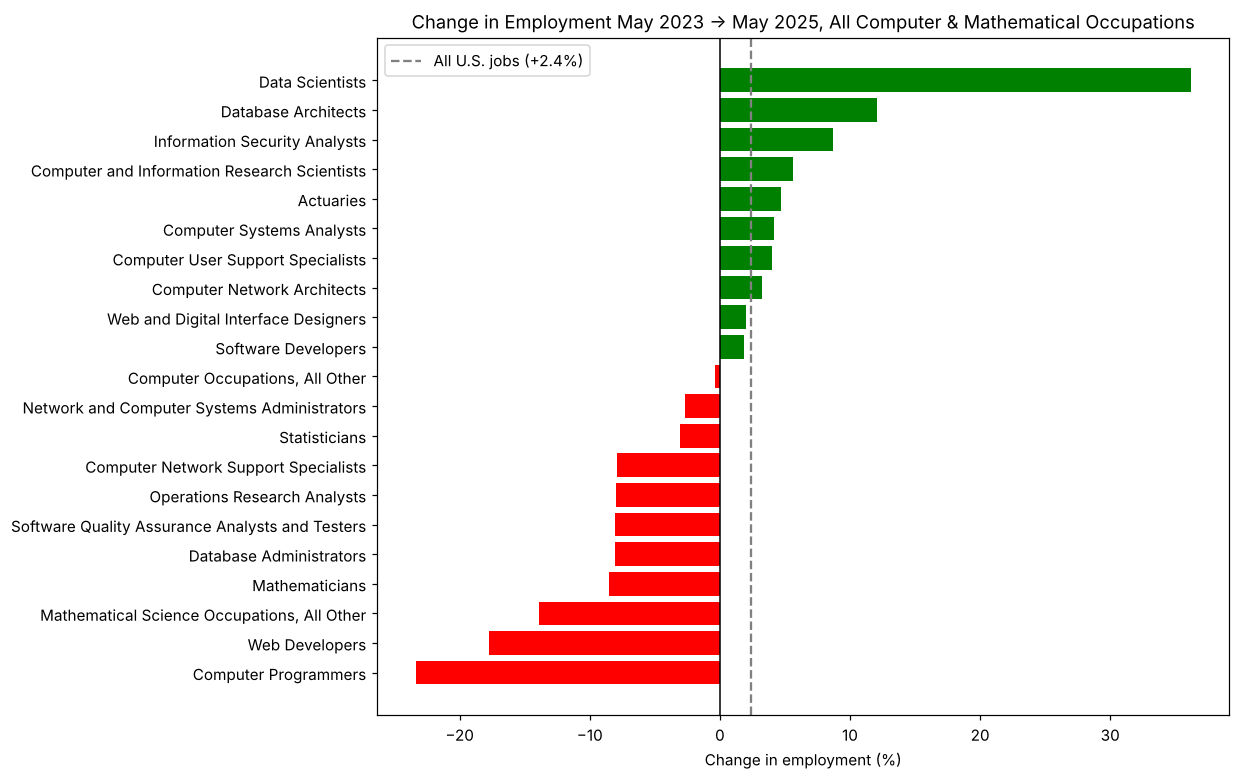

YEAR,2023,2025,Change (%)
OCC_TITLE,,,
Computer Programmers,120370.0,92230.0,-23.4
Web Developers,85350.0,70190.0,-17.8
"Mathematical Science Occupations, All Other",4320.0,3720.0,-13.9
Mathematicians,2220.0,2030.0,-8.6
Database Administrators,76140.0,69990.0,-8.1
Software Quality Assurance Analysts and Testers,203040.0,186740.0,-8.0
Operations Research Analysts,117880.0,108510.0,-7.9
Computer Network Support Specialists,158720.0,146190.0,-7.9
Statisticians,29950.0,29030.0,-3.1


In [12]:
# 2023 and 2025 use exactly the same job codes, so we can compare EVERY computer & maths job directly
tech_jobs = trend[(trend["OCC_CODE"].str.startswith("15-")) & (trend["O_GROUP"] == "detailed")
                  & (trend["YEAR"].isin([2023, 2025]))]
change = tech_jobs.pivot_table(index="OCC_TITLE", columns="YEAR", values="TOT_EMP")
change["Change (%)"] = (change[2025] / change[2023] - 1) * 100
change = change.dropna().sort_values("Change (%)")

colors = ["green" if x > 0 else "red" for x in change["Change (%)"]]

plt.figure(figsize=(10, 8))
plt.barh(change.index, change["Change (%)"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.axvline(2.4, color="grey", linestyle="--", label="All U.S. jobs (+2.4%)")
plt.title("Change in Employment May 2023 → May 2025, All Computer & Mathematical Occupations")
plt.xlabel("Change in employment (%)")
plt.legend()
plt.show()

change.round(1)

- **Objective:** Investigate which jobs are **winning and losing** in the period right after generative AI went mainstream, looking at **every** computer and maths occupation, not only the ones we chose (investigation / comparison).
- **Why this plot:** The values can be **positive or negative**, so a bar chart that diverges from zero (green = growth, red = decline) shows the direction and size of the change at once. Bars are **horizontal** because the job titles are long, and **sorted** so the biggest winners are at the top and the biggest losers at the bottom. We compare May 2023 with May 2025, the two years after ChatGPT, and the job codes are **identical** in both. The grey dashed line shows the growth of all U.S. jobs (+2.4 %).
- **Learning:**
  - **Biggest winner: Data Scientists, +36 %** (192,710 → 262,440), about **15 times** the growth of the whole job market. **Database Architects (+12 %)**, **Information Security Analysts (+9 %)** and **Research Scientists (+6 %)** also grew faster than average. These jobs *build*, *feed* and *protect* AI systems.
  - **Biggest losers: Computer Programmers (−23 %)** and **Web Developers (−18 %)**, followed by **QA Testers (−8 %)** and **Database Administrators (−8 %)**. These jobs involve more **routine, rule-based tasks** (writing standard code, building standard websites, running tests, maintaining databases), which AI tools and automation can increasingly do.
  - **Software Developers grew only +1.9 %**, below the U.S. average. The largest tech job has stopped growing quickly.
  - The pattern suggests that AI is **changing the type of tech work** more than reducing the total amount: demand moved from routine coding towards data, AI and security. It shows a link in time, not proof that AI *caused* the changes.